In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [7]:
df = pd.read_csv('Mall_Customers.csv')
print("Dataset Overview:")
print(df.head())
print(f"\nDataset shape: {df.shape}")
print(df.describe())

Dataset Overview:
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset shape: (200, 5)
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.25

In [8]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002],
       [-1.58632148, -1.4053405 ],
       [-1.58632148,  1.89449216],
       [-1.54815205, -1.36651894],
       [-1.54815205,  1.04041783],
       [-1.54815205, -1.44416206],
       [-1.54815205,  1.11806095],
       [-1.50998262, -0.59008772],
       [-1.50998262,  0.61338066],
       [-1.43364376, -0.82301709],
       [-1.43364376,  1.8556706 ],
       [-1.39547433, -0.59008772],
       [-1.39547433,  0.88513158],
       [-1.3573049 , -1.75473454],
       [-1.3573049 ,  0.88513158],
       [-1.24279661, -1.4053405 ],
       [-1.24279661,  1.23452563],
       [-1.24279661, -0.7065524 ],
       [-1.24279661,  0.41927286],
       [-1.20462718,

In [21]:
# Determine optimal number of clusters using Elbow Method
inertias = []
K = range(1, 11)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

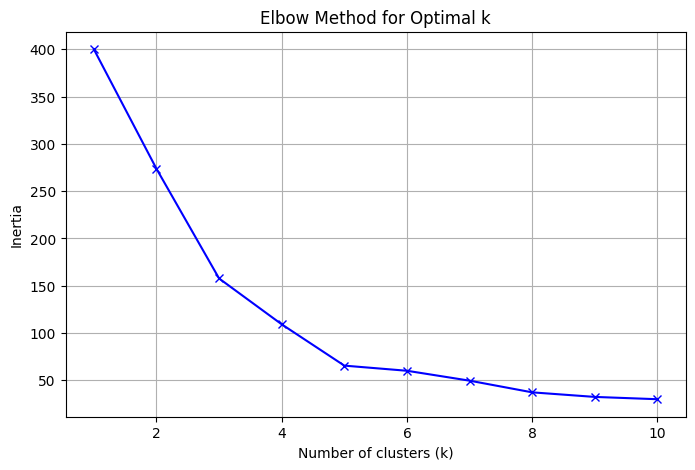

In [22]:
# Plot Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K, inertias, 'bx-')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

In [19]:
# From elbow plot, optimal k = 5 (common for this dataset)
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(X_scaled)
# Add cluster labels to original dataframe
df['Cluster'] = clusters
print("Cluster Centers (scaled):")
print(kmeans.cluster_centers_)
print("Cluster distribution:")
print(df['Cluster'].value_counts())

Cluster Centers (scaled):
[[-0.20091257 -0.02645617]
 [ 0.99158305  1.23950275]
 [-1.32954532  1.13217788]
 [ 1.05500302 -1.28443907]
 [-1.30751869 -1.13696536]]
Cluster distribution:
Cluster
0    81
1    39
3    35
4    23
2    22
Name: count, dtype: int64


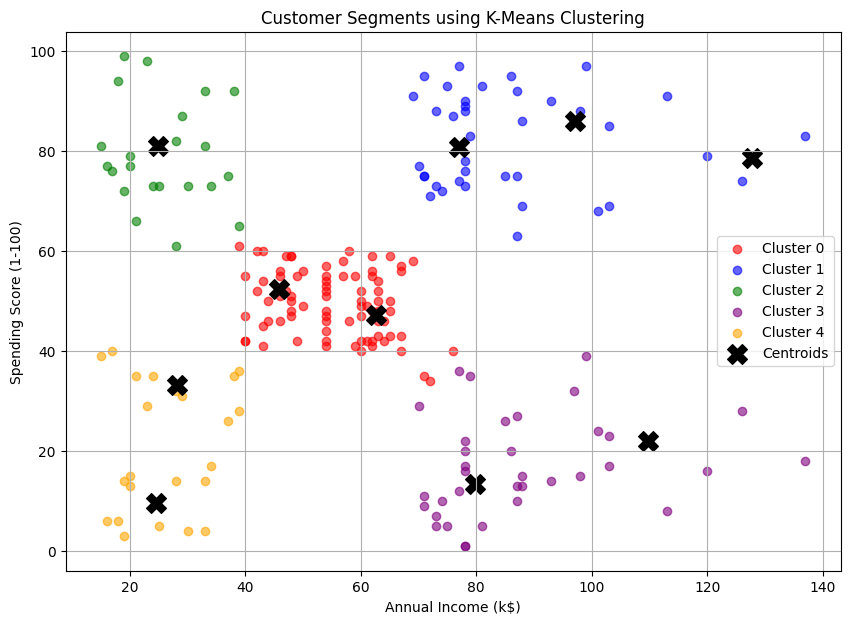

In [23]:
# Visualization of clusters
plt.figure(figsize=(10, 7))
colors = ['red', 'blue', 'green', 'purple', 'orange']
for i in range(optimal_k):
    plt.scatter(X[df['Cluster'] == i]['Annual Income (k$)'],
                X[df['Cluster'] == i]['Spending Score (1-100)'],
                label=f'Cluster {i}', c=colors[i], alpha=0.6)
# Plot centroids (inverse transform to original scale)
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1], s=200, c='black', marker='X', label='Centroids')
plt.title('Customer Segments using K-Means Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(True)
plt.show()

In [24]:
# Business Insights
print("=== Business Insights from Clusters ===")
print("Cluster 0: Medium income, medium spending → Standard customers")
print("Cluster 1: High income, high spending → Target/Premium customers")
print("Cluster 2: Low income, high spending → Carefree/Spenders")
print("Cluster 3: High income, low spending → Careful/Conservative customers")
print("Cluster 4: Low income, low spending → Sensible customers")

=== Business Insights from Clusters ===
Cluster 0: Medium income, medium spending → Standard customers
Cluster 1: High income, high spending → Target/Premium customers
Cluster 2: Low income, high spending → Carefree/Spenders
Cluster 3: High income, low spending → Careful/Conservative customers
Cluster 4: Low income, low spending → Sensible customers
